<a href="https://colab.research.google.com/github/ja2faded/ds2002-fa26/blob/main/2026_11_13_%E2%80%94_Visualization_Challenge_%E2%80%94_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the **same game-day sample** as Monday's lecture. Each one is graded against the **six-point rubric** from Wednesday's studio — use `score()` from that notebook or re-type it here.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart needs a one-line **caption** below it saying what decision it supports.

**Due Wednesday, November 18, 11:59pm ET** in Canvas (pushed back one week for midterm presentations). Use Monday's recipes (`barh`, `lineplot`, `histplot`, `finish()`, etc.) — you do not need new chart types beyond what the cookbook already showed.

In [20]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()


# --- game-day sample (same generator as the Monday lecture) ------------------
rng = np.random.default_rng(2026)
hours = np.arange(9, 22)
build_up = np.exp(-((hours - 14.5) ** 2) / (2 * 2.3 ** 2))
storm = np.exp(-((hours - 17.0) ** 2) / (2 * 1.5 ** 2))
GAMES = {'Sep 5': False, 'Sep 19': False, 'Oct 10': True, 'Nov 14': True}

rows = []
for game, rainy in GAMES.items():
    rain_mm = rainy * (0.4 + 3.0 * storm) * rng.gamma(10, 0.1, len(hours))
    for h, b, rain in zip(hours, build_up, rain_mm):
        n_main = rng.poisson(b * 150 + 12)
        n_rain = rng.poisson(rain * 5 + 0.2)
        cats = np.concatenate([
            rng.choice(['Food', 'Merch', 'Drink'], n_main, p=[.45, .22, .33]),
            np.repeat('RainGear', n_rain),
        ])
        rows += [(game, 'rain' if rainy else 'dry', h, round(rain, 1), c) for c in cats]

df = pd.DataFrame(rows, columns=['game', 'weather', 'hour', 'rain_mm', 'category'])
df['zone'] = rng.choice(['A', 'B', 'C'], len(df), p=[.6, .3, .1])
df['revenue'] = (
    df['category'].map({'Food': 12, 'Merch': 28, 'Drink': 6, 'RainGear': 15})
    * rng.lognormal(-0.18, 0.6, len(df))
).round(2)

print(len(df), 'orders across', df['game'].nunique(), 'games')
df.head()


4364 orders across 4 games


,game,weather,hour,rain_mm,category,zone,revenue
0,Sep 5,dry,9,0.0,Food,C,7.90
1,Sep 5,dry,9,0.0,Food,B,5.46
2,Sep 5,dry,9,0.0,Drink,A,7.93
3,Sep 5,dry,9,0.0,Drink,B,5.68
4,Sep 5,dry,9,0.0,Merch,A,12.75


### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

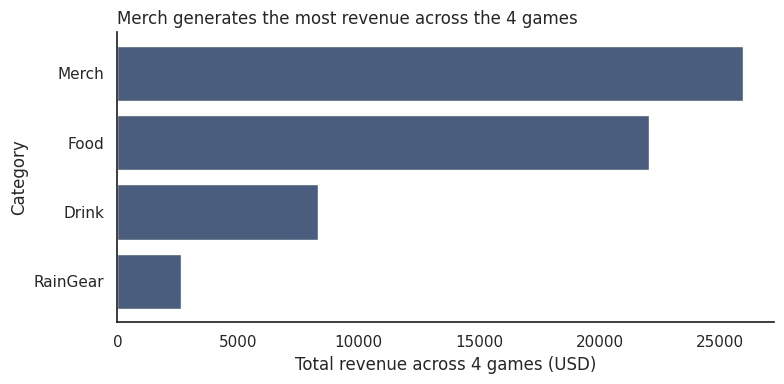

In [21]:
category_revenue = df.groupby('category')['revenue'].sum().sort_values()

fig, ax = plt.subplots(figsize=(8, 4))

ax.barh(category_revenue.index, category_revenue.values, color=BLUE)

ax.set_xlim(left=0)

finish(ax, 'Merch generates the most revenue across the 4 games', 'Total revenue across 4 games (USD)', 'Category')
plt.show()



**Caption: Merch genetates the most revenue across the 4 games. They should prioritize merch inventory and sales coverage.

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

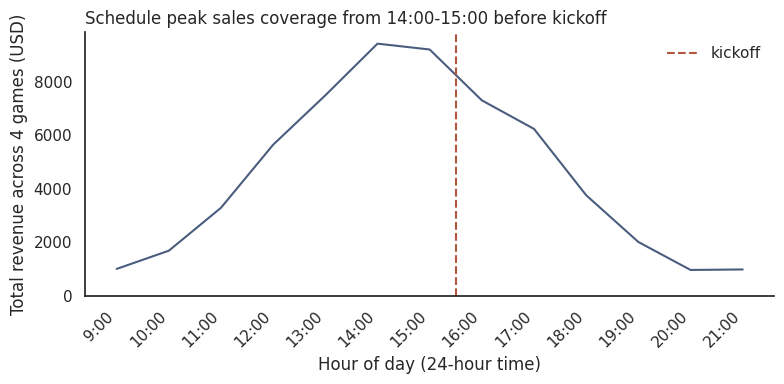

In [22]:
hourly_revenue = df.groupby('hour', as_index=False)['revenue'].sum()

fig, ax = plt.subplots(figsize=(8, 4))

sns.lineplot(data=hourly_revenue, x='hour', y='revenue', ax=ax, color=BLUE)

ax.axvline(15.5, color=RUST, linestyle='--', linewidth=1.5, label="kickoff")

ax.set_xticks(range(9,22))

ax.set_xticklabels(['9:00', '10:00', '11:00', '12:00', '13:00', '14:00', '15:00', '16:00', '17:00', '18:00', '19:00', '20:00', '21:00']
                   , rotation=45, ha='right')

ax.set_ylim(bottom=0)
ax.legend(frameon=False)

finish(ax, 'Schedule peak sales coverage from 14:00-15:00 before kickoff', 'Hour of day (24-hour time)', 'Total revenue across 4 games (USD)')
plt.show()

**Caption: Schedule peak sales coverage around 14:00 to 15:00 before kickoff. THe greatest kickoff sales coverage should be scheduled for this period and coverage should be reduced as rvenue declines later in the evening (and before the peak in the morning).

### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

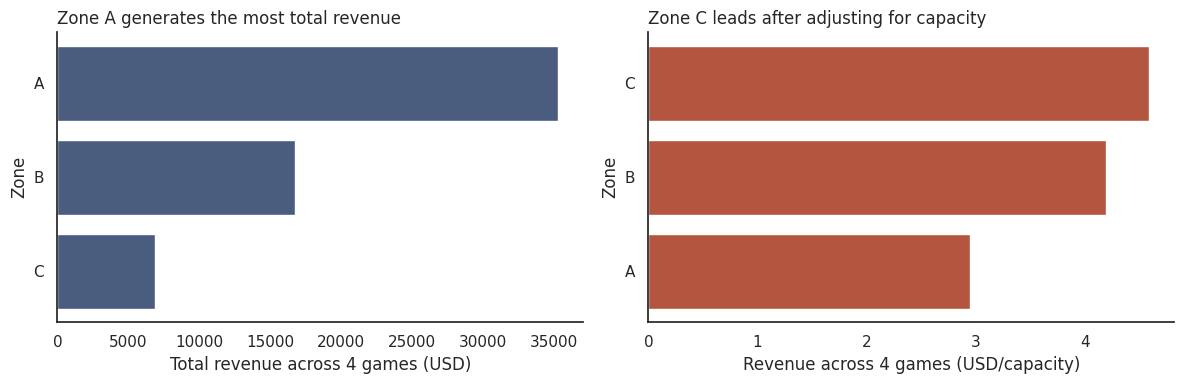

In [23]:
from matplotlib import axes
zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}

zone_summary = (df.groupby('zone')['revenue'].sum().to_frame('revenue'))
zone_summary['capacity'] = pd.Series(zone_capacity)
zone_summary['revenue_per_capacity'] = zone_summary['revenue'] / zone_summary['capacity']

raw=zone_summary.sort_values('revenue')
normalized=zone_summary.sort_values('revenue_per_capacity')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].barh(raw.index, raw['revenue'], color=BLUE)
axes[1].barh(normalized.index, normalized['revenue_per_capacity'], color=RUST)
axes[0].set_xlim(left=0)
axes[1].set_xlim(left=0)

finish(axes[0], 'Zone A generates the most total revenue', 'Total revenue across 4 games (USD)', 'Zone')
finish(axes[1], 'Zone C leads after adjusting for capacity', 'Revenue across 4 games (USD/capacity)', 'Zone')
plt.show()


**Caption, and which panel I would present: They should use total revenue to identify where the most sales dollars are generated and revenue per capacity unit to compare zones relative to their size. I would show the normalized panel and note that Zone C leads after adjusting for capacity. I would also show the raw panel to note that Zone A leads in total revenue overall.

### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

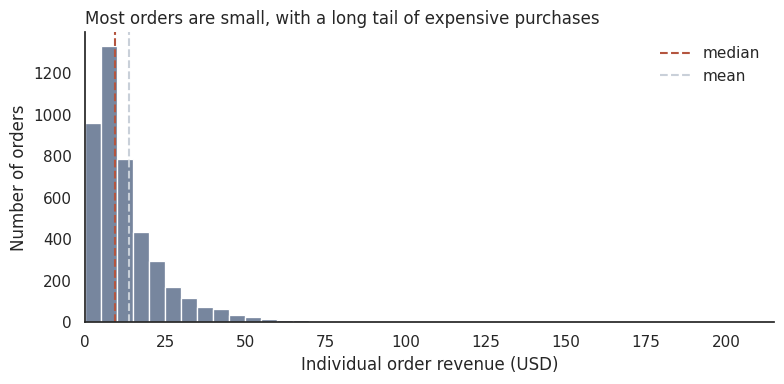

In [24]:
median_revenue = df['revenue'].median()
mean_revenue = df['revenue'].mean()

#round upper edge as mult. of 5 dollars so hist includes every order
upper_edge = np.ceil(df['revenue'].max() / 5) * 5
bins = np.arange(0, upper_edge + 5, 5)

fig, ax = plt.subplots(figsize=(8,4))

sns.histplot(data=df, x='revenue', bins=bins, color=BLUE, ax=ax)

ax.axvline(median_revenue, color=RUST, linestyle='--', linewidth=1.5, label='median')
ax.axvline(mean_revenue, color=GRAY, linestyle='--', linewidth=1.5, label='mean')

ax.set_xlim(0, upper_edge)
ax.set_ylim(bottom=0)
ax.legend(frameon=False)

finish(ax, 'Most orders are small, with a long tail of expensive purchases', 'Individual order revenue (USD)', 'Number of orders')
plt.show()

**Caption:** They should plan regular checkout service around many small purchases, while allowing for occasional large orders. The graph shows a right-skew distribution, meaning there is variaiton and unusually expensive purchases that category totals hode.

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

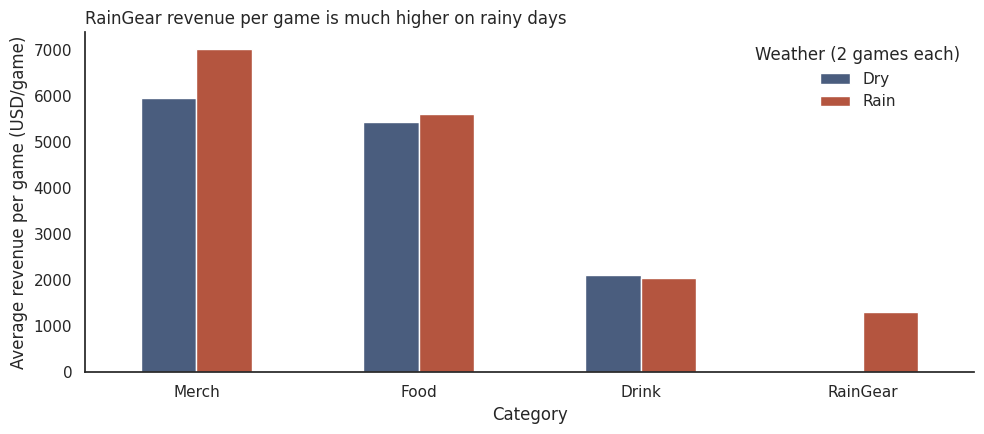

In [25]:
from pandas.core import frame
games_per_weather = (df.groupby('weather' )['game'].nunique())
weather_revenue = (df.groupby(['category','weather'])['revenue'].sum().unstack(fill_value=0))

weather_per_game = weather_revenue.div(games_per_weather, axis='columns')

category_order = (weather_per_game.mean(axis=1).sort_values(ascending=False).index)

plot_data = weather_per_game.loc[category_order, ['dry', 'rain']]

dry_rain_gear = plot_data.loc['RainGear', 'dry']
rainy_rain_gear = plot_data.loc['RainGear', 'rain']

fig, ax = plt.subplots(figsize=(10,4.5))

plot_data.plot.bar(ax=ax, color=[BLUE, RUST], stacked=False, rot=0)

ax.set_ylim(bottom=0)

ax.legend(title = 'Weather (2 games each)', labels = ['Dry', 'Rain'], frameon=False)

finish(ax, 'RainGear revenue per game is much higher on rainy days', 'Category', 'Average revenue per game (USD/game)')
plt.show()





**Caption:** They should increase RainGear availability for rainy forecasts since average RainGear revenue is much higher on rainy game days. However, the comparision includes only 2 games for each weatehr group and cannot establish causation.

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [26]:
scores = {
    'chart 1 (category)': 6,     # TODO: out of 6
    'chart 2 (hour)': 6,
    'chart 3 (zone)': 6,
    'chart 4 (distribution)': 6,
    'chart 5 (your choice)': 6,
}

for name, s in scores.items():
    status = 'unscored' if s is None else ('fix' if s < 5 else 'ok')
    print(f'{name:<26} {s}/6  [{status}]')

filled = [s for s in scores.values() if s is not None]
if filled:
    print(f'\naverage: {sum(filled) / len(filled):.1f}/6')

chart 1 (category)         6/6  [ok]
chart 2 (hour)             6/6  [ok]
chart 3 (zone)             6/6  [ok]
chart 4 (distribution)     6/6  [ok]
chart 5 (your choice)      6/6  [ok]

average: 6.0/6


### Write-up

**a)** Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?

**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.

Chart 3 changed how I interpreted the zones since Zone A originally appeared to perform the best since it had the highest overall revenue at $35,291. However, after dividing by capacity, Zone C ranked number 1 at about $4.58 per capacity unit, higher than Zone A ($2.94).

The raw-revenue chart is appropriate when the manager wants to know which zone contributes the most revenue. One situation this would be useful in is if the manager wanted to know where a sales disruption would have the largest revenue affect. The normalized panel is appropriate when comparing relative revenue capacity across zones of different sizes.